<a href="https://colab.research.google.com/github/BradBalderson/DNACipher/blob/dev/tutorials/DeepVariantImpactMapping.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Variant Impact Mapping (DVIM) Tutorial

Welcome to the tutorial for DVIM with DNACipher, which calls variants with significant predicted effects
at GWAS loci ('impact variants') that are ABOVE background variants confidently un-associated with the trait.

This tutorial will focus on the RUNX3 GWAS locus for Type 1 Diabetes, to regenerate the below figure:
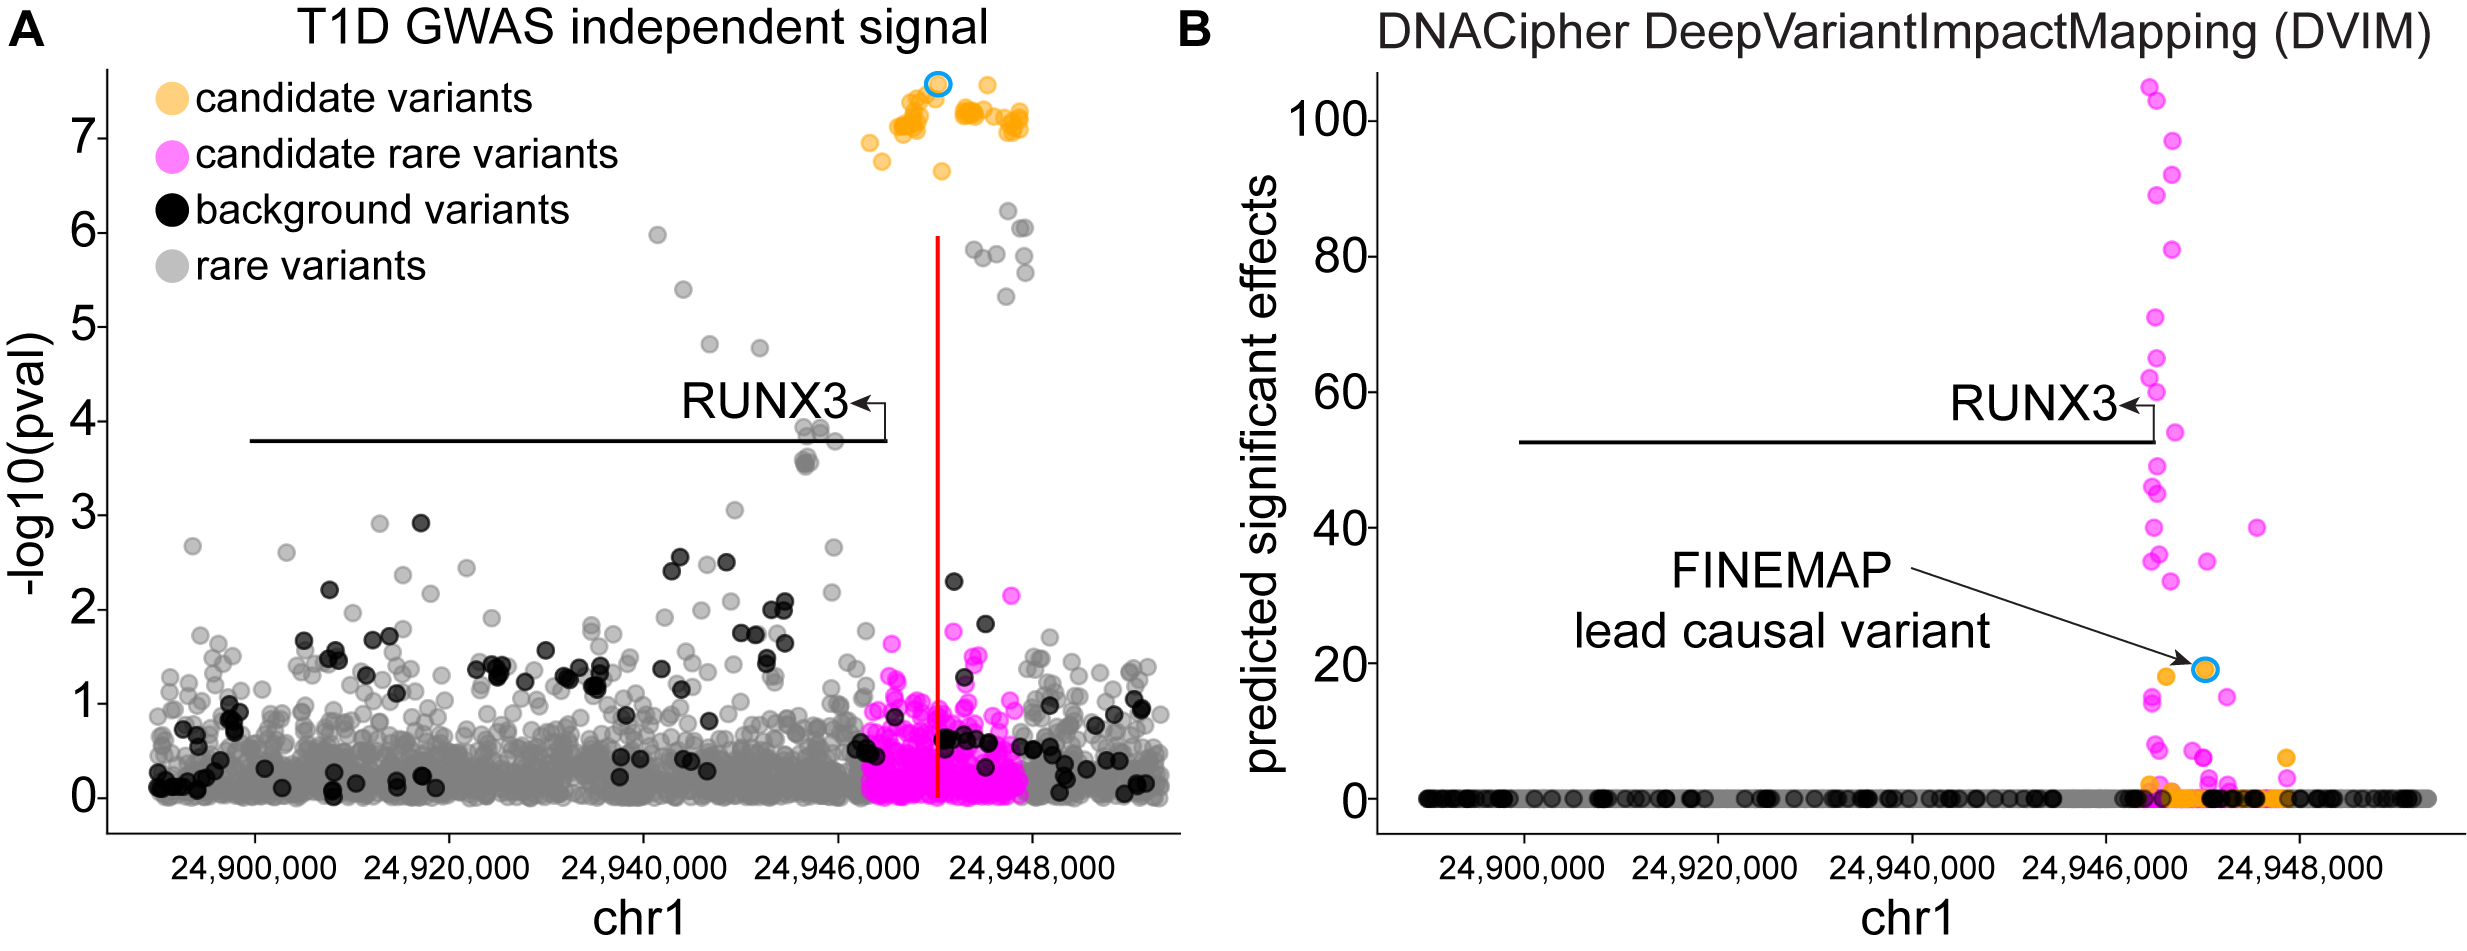

# Compute resources

This notebook can be run on a free T4 GPU, using at most ~4.3Gb of RAM, which can be lowered by adjusting the batch_size parameter.

All times and outputs shown below are for the T4 GPU.

Also tested A100 GPU, which does speed up the below significantly.

CPU and TPU works fine, but is slow & not recommended.

# Installing dependencies
# NOTE if asked to restart collab during isntall below, click NO.

In [50]:
!python --version

Python 3.13.15


In [51]:
!pip install pyfaidx kipoiseq pybedtools

In [52]:
!pip install lightning

In [53]:
!pip install borzoi-pytorch enformer-pytorch

  Using cached numpy-2.5.4-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
Using cached numpy-2.5.4-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.7 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.2.0
    Uninstalling numpy-2.2.0:
      Successfully uninstalled numpy-2.2.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.4 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [54]:
!pip install numpy==2.2 # Important for numba.

  Using cached numpy-2.2.0-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
Using cached numpy-2.2.0-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.1 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
      Successfully uninstalled numpy-2.5.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
enformer-pytorch 0.8.11 requires numpy>=2.3.1, but you have numpy 2.2.0 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [55]:
!apt-get install bedtools # Alternative installations if you have conda, is: conda install bioconda::bedtools

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
bedtools is already the newest version (2.31.1+dfsg-2).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.


In [56]:
#### Installing the dnacipher github
!rm -rf DNACipher
!git clone https://github.com/BradBalderson/DNACipher.git

Cloning into 'DNACipher'...
remote: Enumerating objects: 450, done.
remote: Counting objects: 100% (236/236), done.
remote: Compressing objects: 100% (172/172), done.
remote: Total 450 (delta 130), reused 151 (delta 63), pack-reused 214 (from 1)
Receiving objects: 100% (450/450), 18.70 MiB | 19.98 MiB/s, done.
Resolving deltas: 100% (252/252), done.


In [57]:
!git -C ./DNACipher/ checkout dev

branch 'dev' set up to track 'origin/dev'.
Switched to a new branch 'dev'


In [58]:
!git -C ./DNACipher/ pull

Already up to date.


# Environment Setup

In [59]:
import os, sys

# Setting this, so that below if component not implemented in Pytorch can fall back to CPU.
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'

# Adding DNACipher to the path
sys.path.append('DNACipher')

In [60]:
##### Importing dependencies
import torch

import pickle
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sb

import importlib as imp

import pyfaidx

In [61]:
np.__version__

'2.2.0'

In [62]:
# DNACipher import
import dnacipher.command_line_helpers as dhs
import dnacipher.infer.dna_cipher_infer as dnaci
import dnacipher.infer.deep_variant_impact_mapping as dvim
import dnacipher.visual.dna_cipher_plotting as dnapl

In [63]:
import importlib as imp
imp.reload(dnaci)
imp.reload(dnapl)
imp.reload(dnaci.pybedtools)
imp.reload(dvim)

<module 'dnacipher.infer.deep_variant_impact_mapping' from '/content/DNACipher/dnacipher/infer/deep_variant_impact_mapping.py'>

In [64]:
#### Paths
data_path = 'DNACipher/tutorials/data/'
fasta_file_path = f'{data_path}genome.fa'
gtf_file_path = f'{data_path}gencode.v26.annotation.gtf'
gwas_signal_path = f"{data_path}Chiou-2021-T1D-GWAS_RUNX3-signal_variant_stats.txt.gz"

# Data setup

## Downloading reference genome to load sequences from

Download and index the reference genome fasta file

Credit to Genome Reference Consortium: https://www.ncbi.nlm.nih.gov/grc

Schneider et al 2017 http://dx.doi.org/10.1101/gr.213611.116: Evaluation of GRCh38 and de novo haploid genome assemblies demonstrates the enduring quality of the reference assembly

NOTE sometimes the below link will time out, just wait a few seconds and try to download again.

In [70]:
!mkdir -p {data_path}
!wget -O - http://hgdownload.cse.ucsc.edu/goldenPath/hg38/bigZips/hg38.fa.gz | gunzip -c > {fasta_file_path}
pyfaidx.Faidx(fasta_file_path)
!ls {data_path}

--2026-10-15 02:43:53--  http://hgdownload.cse.ucsc.edu/goldenPath/hg38/bigZips/hg38.fa.gz
Resolving hgdownload.cse.ucsc.edu (hgdownload.cse.ucsc.edu)... 128.114.119.163
Connecting to hgdownload.cse.ucsc.edu (hgdownload.cse.ucsc.edu)|128.114.119.163|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 983659424 (938M) [application/x-gzip]
Saving to: ‘STDOUT’

-                   100%[===================>] 938.09M  11.1MB/s    in 85s     

2026-10-15 02:45:19 (11.0 MB/s) - written to stdout [983659424/983659424]

Chiou-2021-T1D-GWAS_RUNX3-signal_variant_stats.txt.gz  genome.fa.fai
chiou_2021_t1d_gwas_signal_variants.txt		       gtex_variants_SMALL.vcf
genome.fa


## Downloading Gencode gene annotations for visualization

In [71]:
!wget -O - https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_26/gencode.v26.annotation.gtf.gz | gunzip -c > {gtf_file_path}

--2026-10-15 02:45:51--  https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_26/gencode.v26.annotation.gtf.gz
Resolving ftp.ebi.ac.uk (ftp.ebi.ac.uk)... 193.62.193.165
Connecting to ftp.ebi.ac.uk (ftp.ebi.ac.uk)|193.62.193.165|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 37607127 (36M) [application/x-gzip]
Saving to: ‘STDOUT’

-                   100%[===================>]  35.86M   878KB/s    in 35s     

2026-10-15 02:46:26 (1.03 MB/s) - written to stdout [37607127/37607127]



In [72]:
#### Loading the gtf
gtf_cols = [
        "chrom", "source", "feature", "start", "end",
        "score", "strand", "frame", "attribute"
    ]
gtf_df = pd.read_csv(gtf_file_path, sep="\t", header=None, comment='#', names=gtf_cols)
gtf_df = gtf_df.loc[gtf_df["feature"].values=='gene', :]
gtf_df['gene_names'] = gtf_df.apply(lambda x: x.iloc[8].split('gene_name')[1].split('; ')[0].strip(' "'), 1)
gtf_df['gene_ids'] = gtf_df.apply(lambda x: x.iloc[8].split('gene_id')[1].split('; ')[0].strip(' "'), 1)
gene_ids = gtf_df['gene_ids'].values

gtf_df.head(3)

,chrom,source,feature,start,end,score,strand,frame,attribute,gene_names,gene_ids
0,chr1,HAVANA,gene,11869,14409,.,+,.,"gene_id ""ENSG00000223972.5""; gene_type ""transc...",DDX11L1,ENSG00000223972.5
12,chr1,HAVANA,gene,14404,29570,.,-,.,"gene_id ""ENSG00000227232.5""; gene_type ""unproc...",WASH7P,ENSG00000227232.5
25,chr1,ENSEMBL,gene,17369,17436,.,-,.,"gene_id ""ENSG00000278267.1""; gene_type ""miRNA""...",MIR6859-1,ENSG00000278267.1


## Loading the pretrained DNACipher model

The below will by load the DNACipher-Enformer model.

To specify the DNACipher-Borzoi model, we simply change the flag.

If using a newly trained version of DNACipher (see Train.md in the Github repo), you need to specify other necessary inputs if the model is not currently hosted on the github (see ?dhs.load_dnacipher_infer).

In [73]:
dnacipher = dhs.load_dnacipher_infer(fasta_file_path=fasta_file_path,
                                     model_name='enformer', # Or 'borzoi', used enformer for manuscript due to faster compute.
                                     )

Will use cuda GPU
Loading sample_file: /content/DNACipher/dnacipher/weights/encode_meta_encode_imputable_filter-fixed_train-test_samp-probs.borzoi_fold_0.tsv

Loading model weights: /content/DNACipher/dnacipher/weights/ENFORMER_SOFTPLUS_LR_0_model_weights.pth

Loading model config: /content/DNACipher/dnacipher/configs/softplusLR_model_config.yaml


Loading the model_config... has state:

{'n_celltype_factors': 128, 'n_assay_factors': 256, 'n_seq_factors': 128, 'n_layers': 3, 'n_nodes': 512, 'layer_norm': True, 'activation_function': 'gelu', 'out_transform': 'softplus', 'lr_scheduler': True}

Loading the embedding enformer model...

Embedding model is on device: cuda:0

Embedding model details: Model name: enformer.
Input seq length: 196608.
Embed seq length: 114688.
Edge context length: 40960.
Embed seq resolution: 128.
Embed features: 3072.


Successfully loaded DNACipher inference model


In [74]:
### The cell types / tissues represented
pd.DataFrame( dnacipher.celltypes )

,0
0,A549
1,A673
2,ACC112
3,AG04450
4,B cell
...,...
186,upper lobe of left lung
187,upper lobe of right lung
188,urinary bladder
189,uterus


In [75]:
### The assays represented:
pd.DataFrame( dnacipher.assays )

,0
0,AFF4_ChIP-seq
1,ARID3A_ChIP-seq
2,ARNT_ChIP-seq
3,ASH2L_ChIP-seq
4,ATAC-seq
...,...
197,minus strand total RNA-seq
198,plus strand polyA minus RNA-seq
199,plus strand polyA plus RNA-seq
200,plus strand total RNA-seq


# Deep Variant Impact Mapping of the RUNX3 T1D locus

Predicting if, where, and what effect of genetic variants.

In [76]:
# Fine-mapping variants surrounding RUNX3 locus
gene_ = 'RUNX3'
gene_entry = gtf_df.loc[gtf_df['gene_names'].values == gene_, :]
gene_range = list(gene_entry[["chrom","start","end","strand"]].values[0,:])
tss = gene_range[1] if gene_range[3]=="+" else gene_range[2] # Taking start position depending on strand
gene_midpoint = np.mean(gene_range[1:3])

gene_range, tss, gene_midpoint

(['chr1', 24899511, 24965121, '-'], 24965121, np.float64(24932316.0))

Defining a range to take variants from the file, downloaded from Chiou Nature 2021 paper to here.

In [77]:
seq_pred_range = dnacipher.embed_model.embed_seq_len

seq_pred_range

114688

In [78]:
var_pos = 24970252
locus_midpoint = var_pos
variants_range = (locus_midpoint-round(seq_pred_range*.5), locus_midpoint+round(seq_pred_range*.5))
variants_range

(24912908, 25027596)

## NOTE on how I retrieved the T1D GWAS variant information for the RUNX3 locus:

This is how I downloaded the GWAS variant data for the RUNX3 locus:

Need to use the harmonize version for the meta analysis from here:

    https://ftp.ebi.ac.uk/pub/databases/gwas/summary_statistics/GCST90014001-GCST90015000/GCST90014023/harmonised/

Then isolated the variants on chromosome 1, which is where RUNX3 is located.

    (NOTE on unix command-line)
    gzip -d -c 34012112-GCST90014023-EFO_0001359-Build38.f.tsv.gz | awk 'NR==1 || $3 == 1' | gzip -c > 34012112-GCST90014023-EFO_0001359-Build38.f.tsv.chr1.gz
    
Then I read-in the variants on chr1, and subsetted to those at the range defined above for the RUNX3 T1D locus:

(NOTE this is Python)
    
    chr_gwas_stats = pd.read_csv(f"34012112-GCST90014023-EFO_0001359-Build38.f.tsv.{gene_range[0]}.gz", sep='\t')
    
    gene_gwas_variants_bool = np.logical_and(chr_gwas_stats['base_pair_location'].values > variants_range[0],
                                         chr_gwas_stats['base_pair_location'].values < variants_range[1])

    locus_gwas_stats = chr_gwas_stats.loc[gene_gwas_variants_bool, :].copy()
    locus_gwas_stats['-log10_pval'] = -np.log10( locus_gwas_stats['p_value'].values )
    locus_gwas_stats = locus_gwas_stats.iloc[ np.argsort(locus_gwas_stats['base_pair_location'].values), :]

## Loading the variants at this locus that are already saved in the github repo

In [79]:
locus_gwas_stats = pd.read_csv(gwas_signal_path, sep='\t')
locus_gwas_stats.head(3)

,variant_id,p_value,chromosome,base_pair_location,effect_allele,other_allele,effect_allele_frequency,beta,standard_error,odds_ratio,ci_lower,ci_upper,-log10_pval
0,rs117654290,0.0559,1,24913128,A,T,0.000835,-1.808338,0.946013,NaN,NaN,NaN,1.252588
1,rs549964421,0.6050,1,24913148,G,A,0.000052,-2.164790,4.179678,NaN,NaN,NaN,0.218245
2,rs768156233,0.5990,1,24913191,A,G,0.000444,-0.607080,1.154100,NaN,NaN,NaN,0.222573


## Stratifying the variants as candidate common and rare variants, background variants, and other variants.

Performing stratification of variants at GWAS loci to categories:

    * 'candidate' variants (common significant variants)
    * 'rare' variants (non-significant rare variants in the same region as the candidate variants)
    * 'background' variants (common non-significant variants)
    * 'other' variants (rare variants outside of the hit locus).

In [80]:
#### This code addds the column 'var_label' to each varaint according to the above labels.
stratified_gwas_stats = dvim.stratify_variants(locus_gwas_stats)
stratified_gwas_stats.head(3)

No. other variants: 2080
Total selected varaints 618 / 2866
	No. candidate variants: 49
	No. rare variants: 359
	No. background variants: 210


,variant_id,p_value,chromosome,base_pair_location,effect_allele,other_allele,effect_allele_frequency,beta,standard_error,odds_ratio,ci_lower,ci_upper,-log10_pval,var_label
0,rs72657048,1.110000e-07,1,24963243,G,C,0.509,0.074632,0.014060,NaN,NaN,NaN,6.954677,candidate
1,rs6672420,1.740000e-07,1,24964519,T,A,0.483,0.073690,0.014103,NaN,NaN,NaN,6.759451,candidate
2,rs7528484,7.480000e-08,1,24966177,T,C,0.510,0.075321,0.014002,NaN,NaN,NaN,7.126098,candidate


## Plotting the stratification results

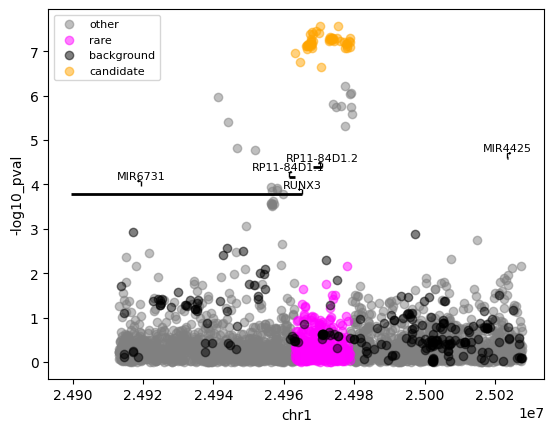

In [81]:
variant_colors = {'other': 'grey', 'candidate': 'orange', 'background': 'black', 'rare': 'magenta'}

dnapl.plot_variant_stats(stratified_gwas_stats, "-log10_pval", "var_label",
                         color_dict=variant_colors, gtf_df=gtf_df)

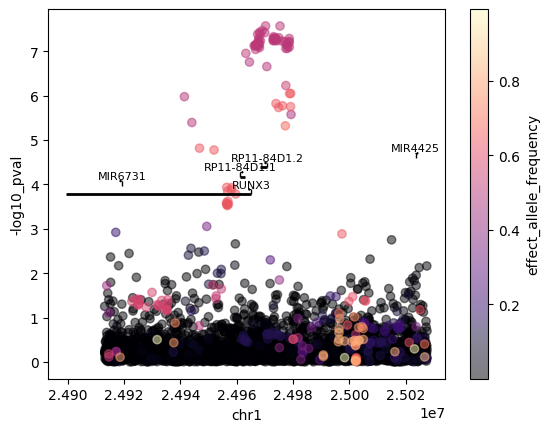

In [82]:
#### Can verify the stratifications by plotting the minor allele frequency!
dnapl.plot_variant_stats(stratified_gwas_stats, "-log10_pval", "effect_allele_frequency",
                         color_dict=variant_colors, gtf_df=gtf_df)

# Running DNACipher variant effect prediction

Setting the sequence position that will be used to centre all query sequences through DNACipher regardless of variant location, so that when scoring the effect we are comparing apples-to-apples between variants.

In [83]:
# Subsetting to just the variants we want to query:
selected_gwas_stats = stratified_gwas_stats.loc[stratified_gwas_stats['var_label'].values!='other'].copy()

### Need to re-arrange the column order in order to satisfy DNACipher variant effect inference input!
new_col_order = ['chromosome', 'base_pair_location', 'other_allele', 'effect_allele']
new_col_order.extend([col for col in selected_gwas_stats.columns if col not in new_col_order])

selected_gwas_stats = selected_gwas_stats.loc[:, new_col_order]
selected_gwas_stats['chromosome'] = [f"chr{chr_}" for chr_ in selected_gwas_stats['chromosome']]

selected_gwas_stats.head(3)

,chromosome,base_pair_location,other_allele,effect_allele,variant_id,p_value,effect_allele_frequency,beta,standard_error,odds_ratio,ci_lower,ci_upper,-log10_pval,var_label
0,chr1,24963243,C,G,rs72657048,1.110000e-07,0.509,0.074632,0.014060,NaN,NaN,NaN,6.954677,candidate
1,chr1,24964519,A,T,rs6672420,1.740000e-07,0.483,0.073690,0.014103,NaN,NaN,NaN,6.759451,candidate
2,chr1,24966177,C,T,rs7528484,7.480000e-08,0.510,0.075321,0.014002,NaN,NaN,NaN,7.126098,candidate


In [84]:
locus_midpoint

24970252

In [85]:
##### Setting where we want to position the query sequence for each variant, so is consistent across all variants to compare
selected_gwas_stats['seq_pos'] = locus_midpoint

Selecting the contexts to make predictions for!

In [86]:
#### NOTE many more immune cells represented in DNACipher (which were tested for the RUNX3-focused analysis)
# But to save computation time will only focus on the broad immune cell types represented when testing across all signals.
immune_cells = ['natural killer cell', 'B cell', 'T-cell']
pancreatic = ['pancreas']

celltypes_to_infer = list(set(immune_cells + pancreatic))
len( celltypes_to_infer )

4

In [87]:
expression_assays = ['minus strand polyA plus RNA-seq', 'plus strand polyA plus RNA-seq',
                     'plus strand total RNA-seq', 'minus strand total RNA-seq']
access_assays = ['ATAC-seq']
histone_assays = ['H3K27ac_ChIP-seq', # active enhancer / promoters
                  'H2BK20ac_ChIP-seq', # very interesting celltype-specific active enhancers
                  'H3K27me3_ChIP-seq'] # repressed regions
tf_assays = ['CTCF_ChIP-seq'] # TAD domains

test_assays = list(set(expression_assays+access_assays+histone_assays+tf_assays))
len(test_assays), test_assays

(9,
 ['plus strand polyA plus RNA-seq',
  'CTCF_ChIP-seq',
  'H3K27me3_ChIP-seq',
  'H2BK20ac_ChIP-seq',
  'ATAC-seq',
  'minus strand total RNA-seq',
  'minus strand polyA plus RNA-seq',
  'H3K27ac_ChIP-seq',
  'plus strand total RNA-seq'])

In [88]:
#### Total effects to infer:
total_expers_to_infer = len(celltypes_to_infer) * len(test_assays)
print(f"Inferring effects for {total_expers_to_infer} experiments out of {len(dnacipher.celltypes)*len(dnacipher.assays)} represented.")

Inferring effects for 36 experiments out of 38582 represented.


In [89]:
#### Total effects to infer:
print("Total number of effects to infer across variants:", (selected_gwas_stats.shape[0] * total_expers_to_infer)/(10**3), "thousand")

Total number of effects to infer across variants: 22.248 thousand


### RUNNING the variant effect inference with DNACipher

NOTE can REDUCE the no. of contexts or variants to reduce computational time.

Alternatively, could use a beefier GPU. On an A40, the below runs in ~5min.

In [ ]:
?dnacipher.infer_multivariant_effects

In [ ]:
selected_pred_effects = dnacipher.infer_multivariant_effects(selected_gwas_stats,
                                                             celltypes_to_infer, test_assays,
                                                     seq_pos_col='seq_pos', # Defines how to centre the query sequences.
                                                     verbose=True,
                                                     # 1-based indexing of variants, if doesn't find expected all allele will throw error
                                                     index_base=1, correct_ref=True,
                                                    )

PROCESSED 0/618 variants in 0.046mins


In [ ]:
selected_pred_effects.head(3)

,natural killer cell---ATAC-seq,natural killer cell---DNase-seq,natural killer cell---plus strand polyA minus RNA-seq,natural killer cell---plus strand polyA plus RNA-seq,natural killer cell---plus strand total RNA-seq,natural killer cell---signal of polyA plus RNA-seq,"naive thymus-derived CD4-positive, alpha-beta T cell---ATAC-seq","naive thymus-derived CD4-positive, alpha-beta T cell---DNase-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA plus RNA-seq",...,"central memory CD8-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand polyA plus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand total RNA-seq","central memory CD8-positive, alpha-beta T cell---signal of polyA plus RNA-seq",T-cell---ATAC-seq,T-cell---DNase-seq,T-cell---plus strand polyA minus RNA-seq,T-cell---plus strand polyA plus RNA-seq,T-cell---plus strand total RNA-seq,T-cell---signal of polyA plus RNA-seq
0,-0.130487,-0.253485,-0.353393,-0.340903,-0.281509,-0.452060,-0.153389,-0.205462,0.369036,0.333374,...,-0.058066,-0.127776,-0.084454,-0.213356,-0.195417,-0.395821,0.303629,0.333257,0.321494,-0.509819
1,-0.900998,-1.649776,-3.080156,-2.747344,-2.516152,-3.959513,-0.955449,-1.208428,-3.160297,3.354201,...,-0.359546,-0.940234,-0.733329,-1.805942,1.186232,-2.047332,-2.674963,3.257060,3.183187,-6.143505
2,-3.384765,-4.674168,-4.061858,-4.133465,-3.131186,-3.069555,-2.660544,2.471774,3.566003,4.335052,...,-0.623898,-1.416211,-0.937075,-1.949609,4.190684,5.156841,-3.058751,-4.128591,-3.237635,-3.163383


# Calculating p-values per molecular effect

Calls variants with significant effect ABOVE non-significant background variants.

In [ ]:
?dvim.calc_variant_effect_pvals

In [ ]:
boot_pvals_df, boot_counts_df = dvim.calc_variant_effect_pvals(selected_gwas_stats, selected_pred_effects,
                                                                                  n_boots=10_000, verbosity=1)

Loading input files.
Separating into background and candidate / rare variants.
Finished boot-strapping for 0 / 10000 (0.0%) in 0.1mins
Finished boot-strapping for 1000 / 10000 (10.0%) in 0.1mins
Finished boot-strapping for 2000 / 10000 (20.0%) in 0.1mins
Finished boot-strapping for 3000 / 10000 (30.0%) in 0.1mins
Finished boot-strapping for 4000 / 10000 (40.0%) in 0.1mins
Finished boot-strapping for 5000 / 10000 (50.0%) in 0.1mins
Finished boot-strapping for 6000 / 10000 (60.0%) in 0.1mins
Finished boot-strapping for 7000 / 10000 (70.0%) in 0.1mins
Finished boot-strapping for 8000 / 10000 (80.0%) in 0.1mins
Finished boot-strapping for 9000 / 10000 (90.0%) in 0.1mins
Finished boot-strapping.

Found 1505 significant effects.
	Total vars with significant effects: 42
	Mean significant effects per significant variant: 35.833333333333336

DONE!


In [ ]:
boot_counts_df.shape

(543, 108)

In [ ]:
boot_counts_df.head(2)

,natural killer cell---ATAC-seq,natural killer cell---DNase-seq,natural killer cell---plus strand polyA minus RNA-seq,natural killer cell---plus strand polyA plus RNA-seq,natural killer cell---plus strand total RNA-seq,natural killer cell---signal of polyA plus RNA-seq,"naive thymus-derived CD4-positive, alpha-beta T cell---ATAC-seq","naive thymus-derived CD4-positive, alpha-beta T cell---DNase-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA plus RNA-seq",...,"central memory CD8-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand polyA plus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand total RNA-seq","central memory CD8-positive, alpha-beta T cell---signal of polyA plus RNA-seq",T-cell---ATAC-seq,T-cell---DNase-seq,T-cell---plus strand polyA minus RNA-seq,T-cell---plus strand polyA plus RNA-seq,T-cell---plus strand total RNA-seq,T-cell---signal of polyA plus RNA-seq
0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,...,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0
1,9998.0,9998.0,6296.0,9330.0,7446.0,7664.0,10000.0,10000.0,9588.0,9833.0,...,9521.0,9824.0,6302.0,7064.0,10000.0,10000.0,9222.0,9371.0,5863.0,5129.0


In [ ]:
# NOTE that these are ALREADY Bonferroni corrected!!!!
boot_pvals_df.head(3)

,natural killer cell---ATAC-seq,natural killer cell---DNase-seq,natural killer cell---plus strand polyA minus RNA-seq,natural killer cell---plus strand polyA plus RNA-seq,natural killer cell---plus strand total RNA-seq,natural killer cell---signal of polyA plus RNA-seq,"naive thymus-derived CD4-positive, alpha-beta T cell---ATAC-seq","naive thymus-derived CD4-positive, alpha-beta T cell---DNase-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA plus RNA-seq",...,"central memory CD8-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand polyA plus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand total RNA-seq","central memory CD8-positive, alpha-beta T cell---signal of polyA plus RNA-seq",T-cell---ATAC-seq,T-cell---DNase-seq,T-cell---plus strand polyA minus RNA-seq,T-cell---plus strand polyA plus RNA-seq,T-cell---plus strand total RNA-seq,T-cell---signal of polyA plus RNA-seq
0,1.0000,1.0000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.0000,1.000000,1.000000,1.000000,1.000000,1.000000
1,0.9998,0.9998,0.629637,0.933007,0.744626,0.766423,1.000000,1.000000,0.958804,0.983302,...,0.952105,0.982402,0.630237,0.706429,1.0000,1.000000,0.922208,0.937106,0.586341,0.512949
2,0.0001,0.0001,0.039296,0.165483,0.195280,0.989901,0.007099,0.708229,0.795720,0.621038,...,0.000100,0.093091,0.021098,0.449355,0.0001,0.136186,0.683132,0.408159,0.528347,0.999900


# Calling significant effects

In [ ]:
sig_effects, foldchange_effects = dvim.call_sig_effects(selected_gwas_stats, selected_pred_effects, boot_pvals_df, fc_cutoff=2)

In [ ]:
sig_effects.head(2)

,natural killer cell---ATAC-seq,natural killer cell---DNase-seq,natural killer cell---plus strand polyA minus RNA-seq,natural killer cell---plus strand polyA plus RNA-seq,natural killer cell---plus strand total RNA-seq,natural killer cell---signal of polyA plus RNA-seq,"naive thymus-derived CD4-positive, alpha-beta T cell---ATAC-seq","naive thymus-derived CD4-positive, alpha-beta T cell---DNase-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA plus RNA-seq",...,"central memory CD8-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand polyA plus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand total RNA-seq","central memory CD8-positive, alpha-beta T cell---signal of polyA plus RNA-seq",T-cell---ATAC-seq,T-cell---DNase-seq,T-cell---plus strand polyA minus RNA-seq,T-cell---plus strand polyA plus RNA-seq,T-cell---plus strand total RNA-seq,T-cell---signal of polyA plus RNA-seq
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
foldchange_effects.head(2)

,natural killer cell---ATAC-seq,natural killer cell---DNase-seq,natural killer cell---plus strand polyA minus RNA-seq,natural killer cell---plus strand polyA plus RNA-seq,natural killer cell---plus strand total RNA-seq,natural killer cell---signal of polyA plus RNA-seq,"naive thymus-derived CD4-positive, alpha-beta T cell---ATAC-seq","naive thymus-derived CD4-positive, alpha-beta T cell---DNase-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","naive thymus-derived CD4-positive, alpha-beta T cell---plus strand polyA plus RNA-seq",...,"central memory CD8-positive, alpha-beta T cell---plus strand polyA minus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand polyA plus RNA-seq","central memory CD8-positive, alpha-beta T cell---plus strand total RNA-seq","central memory CD8-positive, alpha-beta T cell---signal of polyA plus RNA-seq",T-cell---ATAC-seq,T-cell---DNase-seq,T-cell---plus strand polyA minus RNA-seq,T-cell---plus strand polyA plus RNA-seq,T-cell---plus strand total RNA-seq,T-cell---signal of polyA plus RNA-seq
0,-0.165515,-0.324673,-0.377171,-0.370812,-0.313318,-0.496536,-0.160154,-0.152552,0.592591,0.485746,...,-0.047161,-0.096018,-0.058915,-0.233319,-0.240089,-0.490544,0.447943,0.505072,0.493472,-0.422707
1,-0.936026,-1.720963,-3.103934,-2.777253,-2.547960,-4.003989,-0.962214,-1.155518,-2.936742,3.506573,...,-0.348640,-0.908476,-0.707790,-1.825905,1.141559,-2.142055,-2.530649,3.428875,3.355165,-6.056393


As mentioned in the manuscript, we generally observe that rare variants have much higher and more significant predicted molecular effects! See Volcano plot below.

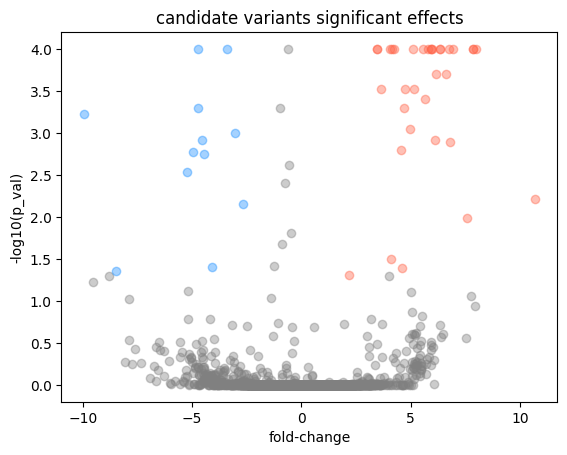

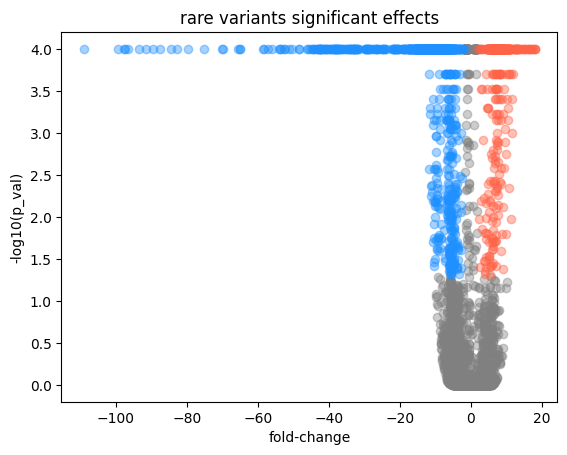

In [ ]:
dnapl.plot_volcano('candidate', selected_gwas_stats, sig_effects, foldchange_effects, boot_pvals_df)
dnapl.plot_volcano('rare', selected_gwas_stats, sig_effects, foldchange_effects, boot_pvals_df)

# Visualiing the Impact Mapping at the locus

In [ ]:
#### In this case, take as s
n_sig_effects = (sig_effects).sum(axis=1)
n_sig_effects.shape

(543,)

In [ ]:
selected_gwas_stats['n_sig_effects'] = n_sig_effects.values
selected_gwas_stats['n_sig_effects'].dtype

dtype('int64')

In [ ]:
# The top impact variants, rs10751776 at position chr1:24970252 is the highest FINEMAP variant at this locus
selected_gwas_stats.loc[n_sig_effects>5,:].head(5)

,chromosome,base_pair_location,other_allele,effect_allele,variant_id,p_value,effect_allele_frequency,beta,standard_error,odds_ratio,ci_lower,ci_upper,-log10_pval,var_label,seq_pos,n_sig_effects
2,chr1,24966177,C,T,rs7528484,7.480000e-08,0.510000,0.075321,0.014002,NaN,NaN,NaN,7.126098,candidate,24970252,18
23,chr1,24970252,A,C,rs10751776,2.670000e-08,0.510000,0.078145,0.014050,NaN,NaN,NaN,7.573489,candidate,24970252,19
45,chr1,24978623,T,C,rs6600247,5.910000e-08,0.508000,0.076164,0.014048,NaN,NaN,NaN,7.228413,candidate,24970252,6
81,chr1,24964466,G,A,rs548250481,2.610000e-01,0.001290,0.745023,0.663360,NaN,NaN,NaN,0.583359,rare,24970252,61
82,chr1,24964514,C,T,rs200345680,3.550000e-01,0.000064,1.612349,1.744282,NaN,NaN,NaN,0.449772,rare,24970252,105


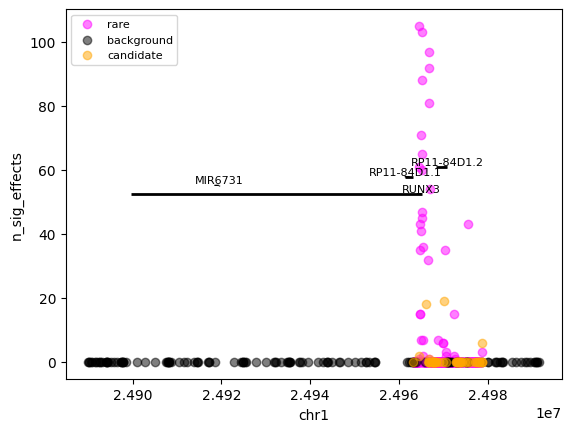

In [ ]:
dnapl.plot_variant_stats(selected_gwas_stats, "n_sig_effects", "var_label",
                         color_dict=variant_colors, gtf_df=gtf_df)

To do this across many different loci, recommend using the commandline interface so can run many loci in parallel more easily. Albeit you will need multiple GPU to run the DNACipher inference steps in parallel.